# WIA3003: Academic Project II
## CNN Baseline Model


## 1.0 Import Required Packages

If required, install the packages in a separate cell:

```python
%pip install tensorflow pandas scikit-learn matplotlib xlrd joblib
```

Restart the kernel after installation.


In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
import json, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
print('TensorFlow version:', tf.__version__)


TensorFlow version: 2.22.0-rc0


## 2.0 Dataset Preparation

### 2.1 Load Dataset and Saved Split


In [5]:
current_folder = Path.cwd()
project_folder = current_folder.parent if current_folder.name == 'notebooks' else current_folder
assert (project_folder / 'notebooks').is_dir(), 'Run from the project or notebooks folder.'
data_path = Path.home() / 'Downloads' / 'Orbital, Nasal and Craniofacial Class Pattern.xls'
split_path = project_folder / 'results' / 'grouped_baselines' / 'split.json'
output_folder = project_folder / 'results' / 'cnn_baseline'
output_folder.mkdir(parents=True, exist_ok=True)
with open(split_path, encoding='utf-8') as file:
    split_details = json.load(file)
# A workbook save can change its file hash. Recheck baselines below if it changed.
dataset_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
workbook_changed = dataset_hash != split_details['dataset_sha256']
if workbook_changed:
    print('Workbook file changed. Baselines will be refitted on the current data.')
df = pd.read_excel(data_path, sheet_name='Raw Data')
df.columns = df.columns.str.replace(r'\s+', ' ', regex=True).str.strip()
features = split_details['features']
X = df[features].apply(pd.to_numeric, errors='raise')
y = df['Gender'].astype('string').str.strip().map(split_details['label_mapping'])
assert not X.isna().any().any()
assert np.isfinite(X.to_numpy()).all()
assert not y.isna().any()
y = y.astype(int)
print('Input shape:', X.shape)
print('Label mapping:', split_details['label_mapping'])


Workbook file changed. Baselines will be refitted on the current data.
Input shape: (1042, 8)
Label mapping: {'F': 0, 'M': 1}


### 2.2 Train-Test Split

Reuse the grouped split from the baseline experiment.


In [7]:
train_indices = np.array(split_details['train_row_positions'], dtype=int)
test_indices = np.array(split_details['test_row_positions'], dtype=int)
assert not (set(train_indices) & set(test_indices))
assert np.array_equal(np.sort(np.concatenate([train_indices, test_indices])), np.arange(len(X)))
X_train, X_test = X.iloc[train_indices].copy(), X.iloc[test_indices].copy()
y_train, y_test = y.iloc[train_indices].copy(), y.iloc[test_indices].copy()
groups = X.groupby(features, sort=False, dropna=False).ngroup()
assert not (set(groups.iloc[train_indices]) & set(groups.iloc[test_indices]))
print('Training:', X_train.shape)
print('Testing:', X_test.shape)
display(pd.DataFrame({'Training': y_train.value_counts(), 'Testing': y_test.value_counts()})
        .rename(index={0: 'Female', 1: 'Male'}))


Training: (832, 8)
Testing: (210, 8)


,Training,Testing
Gender,,
Male,469,118
Female,363,92


### 2.3 Baseline Model Checking

Refit MLP and XGBoost on the current workbook using the saved split. Compare their results with the earlier experiment. A changed workbook file hash does not necessarily mean the measurements changed.


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

reference_models = {
    'MLP': Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu',
                              max_iter=1000, random_state=42)),
    ]),
    'XGBoost': XGBClassifier(objective='binary:logistic', eval_metric='logloss',
        n_estimators=100, max_depth=3, learning_rate=0.1, subsample=1.0,
        colsample_bytree=1.0, tree_method='hist', random_state=42, n_jobs=1),
}
reference_rows = []
for name, reference_model in reference_models.items():
    reference_model.fit(X_train, y_train)
    predicted = reference_model.predict(X_test)
    male_column = list(reference_model.classes_).index(1)
    probabilities = reference_model.predict_proba(X_test)[:, male_column]
    reference_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision (Male)': precision_score(y_test, predicted, zero_division=0),
        'Recall (Male)': recall_score(y_test, predicted, zero_division=0),
        'F1 (Male)': f1_score(y_test, predicted, zero_division=0),
        'Macro F1': f1_score(y_test, predicted, average='macro', zero_division=0),
        'ROC AUC': roc_auc_score(y_test, probabilities),
    })
baseline_results = pd.DataFrame(reference_rows).set_index('Model')
previous_results = pd.read_csv(project_folder / 'results' / 'grouped_baselines' /
                               'model_comparison.csv', index_col='Model')
print('Current-data baselines match earlier metrics:',
      np.allclose(baseline_results.loc[previous_results.index, previous_results.columns],
                  previous_results, rtol=1e-6, atol=1e-8))
display(baseline_results.round(4))
baseline_results.to_csv(output_folder / 'rechecked_baselines.csv')


Current-data baselines match earlier metrics: True


,Accuracy,Precision (Male),Recall (Male),F1 (Male),Macro F1,ROC AUC
Model,,,,,,
MLP,0.7143,0.7266,0.7881,0.7561,0.7056,0.7698
XGBoost,0.7905,0.7891,0.8559,0.8211,0.7841,0.8636


## 3.0 Data Pre-processing

### 3.1 Validation Split and Normalization

Take validation records from the training set. Keep matching measurement groups together. Fit the scaler using the fitting subset only.


In [11]:
validation_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
fit_positions, val_positions = next(validation_splitter.split(
    X_train, y_train, groups=groups.iloc[train_indices]))
assert not (set(groups.iloc[train_indices[fit_positions]]) & set(groups.iloc[train_indices[val_positions]]))
assert y_train.iloc[fit_positions].nunique() == 2
assert y_train.iloc[val_positions].nunique() == 2
selection_scaler = StandardScaler()
X_fit_cnn = selection_scaler.fit_transform(X_train.iloc[fit_positions]).astype('float32')[..., None]
X_val_cnn = selection_scaler.transform(X_train.iloc[val_positions]).astype('float32')[..., None]
y_fit = y_train.iloc[fit_positions].to_numpy(dtype='float32')
y_val = y_train.iloc[val_positions].to_numpy(dtype='float32')
print('Fitting:', X_fit_cnn.shape)
print('Validation:', X_val_cnn.shape)


Fitting: (664, 8, 1)
Validation: (168, 8, 1)


## 4.0 Classical Baseline CNN Model

### 4.1 Model Architecture

Use a small 1D CNN with the eight measurements in a fixed order. The measurements are not images or a time series. The assumption that neighbouring features contain useful patterns needs justification.

Reference: https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv1D


In [13]:
def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(features), 1)),
        tf.keras.layers.Conv1D(16, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling1D(pool_size=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
selection_model = build_cnn()
selection_model.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 8, 16)          │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴─────────────────────

### 4.2 Model Training and Validation

Select the number of epochs using validation loss. Do not use the test set for this selection.


Selected epochs: 40


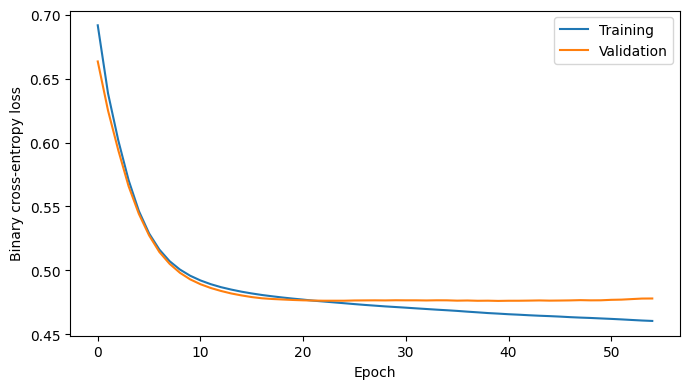

In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)
history = selection_model.fit(X_fit_cnn, y_fit,
    validation_data=(X_val_cnn, y_val), epochs=150, batch_size=32,
    callbacks=[early_stopping], verbose=0)
best_epoch = int(np.argmin(history.history['val_loss']) + 1)
print('Selected epochs:', best_epoch)
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.legend()
plt.tight_layout()
plt.savefig(output_folder / 'training_history.png', dpi=200)
plt.show()


### 4.3 Final Model Training

Fit a new scaler and CNN on all outer training records using the selected number of epochs.


In [17]:
scaler = StandardScaler()
X_train_cnn = scaler.fit_transform(X_train).astype('float32')[..., None]
X_test_cnn = scaler.transform(X_test).astype('float32')[..., None]
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
cnn_model = build_cnn()
cnn_model.fit(X_train_cnn, y_train.to_numpy(dtype='float32'),
              epochs=best_epoch, batch_size=32, verbose=0)
print('CNN training completed.')


CNN training completed.


### 4.4 Model Evaluation

Female = 0 and male = 1. Use a prediction threshold of 0.5. Precision, recall and binary F1 refer to male.


              precision    recall  f1-score   support

      Female     0.8125    0.7065    0.7558        92
        Male     0.7923    0.8729    0.8306       118

    accuracy                         0.8000       210
   macro avg     0.8024    0.7897    0.7932       210
weighted avg     0.8012    0.8000    0.7979       210



,Accuracy,Precision (Male),Recall (Male),F1 (Male),Macro F1,ROC AUC
CNN,0.8,0.7923,0.8729,0.8306,0.7932,0.8575


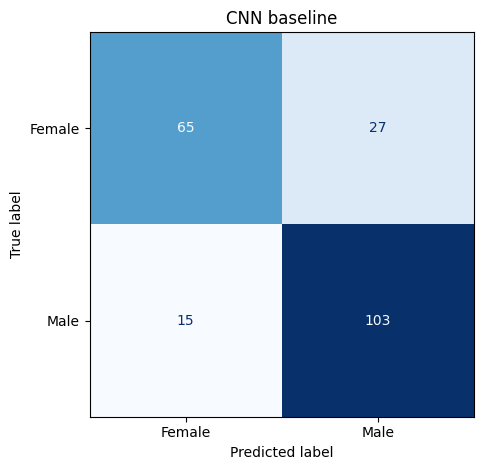

In [19]:
probability_male = cnn_model.predict(X_test_cnn, verbose=0).ravel()
predictions = (probability_male >= 0.5).astype(int)
cnn_metrics = {
    'Accuracy': accuracy_score(y_test, predictions),
    'Precision (Male)': precision_score(y_test, predictions, zero_division=0),
    'Recall (Male)': recall_score(y_test, predictions, zero_division=0),
    'F1 (Male)': f1_score(y_test, predictions, zero_division=0),
    'Macro F1': f1_score(y_test, predictions, average='macro', zero_division=0),
    'ROC AUC': roc_auc_score(y_test, probability_male),
}
display(pd.DataFrame([cnn_metrics], index=['CNN']).round(4))
print(classification_report(y_test, predictions, labels=[0, 1],
    target_names=['Female', 'Male'], digits=4, zero_division=0))
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Female', 'Male']).plot(
    cmap='Blues', values_format='d', colorbar=False)
plt.title('CNN baseline')
plt.tight_layout()
plt.savefig(output_folder / 'confusion_matrix.png', dpi=200)
plt.show()


### 4.5 Model Comparison


In [21]:
comparison = pd.concat([baseline_results,
    pd.DataFrame([cnn_metrics], index=pd.Index(['CNN'], name='Model'))])
display(comparison.round(4))


,Accuracy,Precision (Male),Recall (Male),F1 (Male),Macro F1,ROC AUC
Model,,,,,,
MLP,0.7143,0.7266,0.7881,0.7561,0.7056,0.7698
XGBoost,0.7905,0.7891,0.8559,0.8211,0.7841,0.8636
CNN,0.8000,0.7923,0.8729,0.8306,0.7932,0.8575


## 5.0 Save Model and Results

Save the architecture, weights and scaler separately. The architecture and weights must be loaded together for prediction.


In [23]:
# Store architecture and weights separately for portable reloading.
(output_folder / 'cnn_architecture.json').write_text(cnn_model.to_json(), encoding='utf-8')
np.savez_compressed(output_folder / 'cnn_weights.npz', *cnn_model.get_weights())
joblib.dump(scaler, output_folder / 'scaler.joblib')
comparison.to_csv(output_folder / 'model_comparison.csv')
pd.DataFrame([cnn_metrics]).to_csv(output_folder / 'metrics.csv', index=False)
pd.DataFrame(history.history).to_csv(output_folder / 'training_history.csv', index=False)
pd.DataFrame(cm, index=['Actual Female', 'Actual Male'],
    columns=['Predicted Female', 'Predicted Male']).to_csv(output_folder / 'confusion_matrix.csv')
pd.DataFrame({'source_row_position': test_indices, 'actual_label': y_test.to_numpy(),
    'predicted_label': predictions, 'probability_male': probability_male}).to_csv(
    output_folder / 'test_predictions.csv', index=False)
run_details = {
    'dataset_sha256': dataset_hash,
    'original_split_workbook_sha256': split_details['dataset_sha256'],
    'workbook_file_changed': workbook_changed, 'features': features,
    'label_mapping': split_details['label_mapping'],
    'train_row_positions': train_indices.tolist(), 'test_row_positions': test_indices.tolist(),
    'fit_row_positions': train_indices[fit_positions].tolist(),
    'validation_row_positions': train_indices[val_positions].tolist(),
    'random_state': 42, 'selected_epochs': best_epoch, 'epoch_limit': 150,
    'patience': 15, 'batch_size': 32, 'threshold': 0.5,
    'model_config': json.loads(cnn_model.to_json()),
    'metrics': {key: float(value) for key, value in cnn_metrics.items()},
    'tensorflow_version': tf.__version__, 'sklearn_version': sklearn.__version__,
    'python_version': platform.python_version(),
}
with open(output_folder / 'run_details.json', 'w', encoding='utf-8') as file:
    json.dump(run_details, file, indent=2)
print('Saved to:', output_folder)


Saved to: C:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\cnn_baseline


### 5.1 Saved Model Checking


In [25]:
loaded_model = tf.keras.models.model_from_json(
    (output_folder / 'cnn_architecture.json').read_text(encoding='utf-8'))
with np.load(output_folder / 'cnn_weights.npz', allow_pickle=False) as saved_weights:
    loaded_model.set_weights([saved_weights[f'arr_{i}'] for i in range(len(saved_weights.files))])
loaded_scaler = joblib.load(output_folder / 'scaler.joblib')
loaded_inputs = loaded_scaler.transform(X_test).astype('float32')[..., None]
loaded_probabilities = loaded_model.predict(loaded_inputs, verbose=0).ravel()
np.testing.assert_allclose(probability_male, loaded_probabilities, rtol=1e-5, atol=1e-6)
assert np.array_equal(predictions, (loaded_probabilities >= 0.5).astype(int))
print('Saved model and scaler loaded successfully; predictions match.')


Saved model and scaler loaded successfully; predictions match.


## 6.0 Results and Discussion

The CNN achieved 80.00% accuracy and 79.32% macro F1 on 210 test records. MLP achieved 71.43% accuracy and XGBoost achieved 79.05%. The CNN classified two more records correctly than XGBoost on this split.

All models used the same grouped train-test split. The CNN used an inner grouped validation split to select 40 epochs before training again on the full training set.

These results cover one split and one CNN seed. They do not establish that CNN is generally better. The feature order is fixed, but its suitability for convolution requires discussion.

Two records have identical measurements and conflicting sex labels. Both original labels were retained, and the records were kept in the same partition. Verification with the data provider is still pending. Grouping exact measurement matches alone does not guarantee that all records are from independent subjects.

### 6.1 AI Usage

Codex assisted with preparing and checking this notebook. Review the implementation and results, and record the assistance in the project declaration.
